## Workshop General Info

This is the 5th workshop assignment, worth 1.2 CATs in total. Please note that we provide helper code only, which we expect you to use after suitable modifications, to carry out the tasks in the assignment. We ask you to submit a written report, based on the computational experiments you ran. Please also include a downloaded HTML copy of this notebook, which should include the code you used to run the experiments and the code for creating the graphs.  We will use this to verify that your code generated the plots used in your report.

### Instructions for packages
Please use the Standard Python 3 environment and run the following cells to install the appropriate packages. If you get errors, it could be due to package clashes. A possible workaround is opening a terminal and executing

```
mv ~/.local ~/.local_260320 # or any unique directory name
```

which gives you a blank slate for your packages. If you need to restore the previous state you can achieve that by doing

```
mv ~/.local_260320 ~/.local # 
```
**WARNING:** only try this if `pip` complains about packages being incompatible **and** getting unexpected errors when running the code.

In [1]:
import sys
sys.path.append('/home/jovyan/.local/lib/python3.12/site-packages/')

In [2]:
pip install --user deepcomparer

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install --user jax cuthbert

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install --user chess python-chess

Note: you may need to restart the kernel to use updated packages.


#### Disclaimer

This guide is adapted from the `cuthbert` package [Quick Start guide](https://state-space-models.github.io/cuthbert/quickstart) but reduced to allow running the code on Noteable. Feel free to modify the parameters but expect kernel crashes, probably due to insufficient RAM on the server.

This guide will get you up and running with cuthbert for state-space model inference. We'll walk through an example of ranking international football teams over time using a linearized Kalman filter.

#### Imports

In [5]:
from typing import NamedTuple

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from jax import Array, vmap
from jax import numpy as jnp
from jax.nn import sigmoid
from jax.scipy.stats import norm

from cuthbert import filter, smoother
from cuthbert.gaussian import taylor
from cuthbertlib.types import LogConditionalDensity, LogDensity

#### Load data
We're going to need historical data from international football matches including the dates of the matches, which teams played, and the result (draw, home win, away win). Luckily, there's a very handy dataset of international football match results available on [GitHub](https://github.com/martj42/international_results).

In [6]:
def load_international_football_data(
    start_date: str = "1872-11-30",
    end_date: str | None = None,
    origin_date: str | None = None,
    min_matches: int = 0,
) -> tuple[pd.DataFrame, dict[int, str], dict[str, int]]:
    """
    Load international football match result data.

    Sourced with gratitude from the very handy:
    https://github.com/martj42/international_results

    Requires internet connection to read the data.

    Args:
        start_date: The start date of the data to load.
            Defaults to the apparent start of international football "1872-11-30".
            Required in "YYYY-MM-DD" format.
        end_date: The end date of the data to load. Defaults to today's date
            Required in "YYYY-MM-DD" format.
        origin_date: The date to use as the zero point the output timestamps. Defaults
            to start_date. Required in "YYYY-MM-DD" format.
        min_matches: The minimum number of matches a team must have to be included.

    Returns:
        A tuple of match times, match team indices,
            match results (0 for draw, 1 for home win, 2 for away win),
            teams id to name dictionary, and teams name to id dictionary.
    """
    if end_date is None:
        end_date = pd.Timestamp.today().strftime("%Y-%m-%d")

    if origin_date is None:
        origin_date = start_date

    origin_timestamp = pd.to_datetime(origin_date)

    data_url = "https://raw.githubusercontent.com/martj42/international_results/master/results.csv"
    data_all = pd.read_csv(data_url)

    # Process time data into days since origin date
    data_all["date"] = pd.to_datetime(data_all["date"])
    data_all["timestamp_days"] = (data_all["date"] - origin_timestamp).dt.days
    data_all = data_all[
        (data_all["date"] >= start_date) & (data_all["date"] <= end_date)
    ]

    # Filter teams with fewer than min_matches
    home_counts: pd.Series = data_all["home_team"].value_counts()
    away_counts: pd.Series = data_all["away_team"].value_counts()
    total_counts = home_counts.add(away_counts, fill_value=0)
    valid_teams = set(total_counts[total_counts >= min_matches].index)
    data_all = data_all[
        data_all["home_team"].isin(list(valid_teams))
        & data_all["away_team"].isin(list(valid_teams))
    ]

    # Build team dictionaries and IDs
    teams_arr = sorted(valid_teams)
    teams_name_to_id_dict = {a: i for i, a in enumerate(teams_arr)}
    teams_id_to_name_dict = {i: a for i, a in enumerate(teams_arr)}
    data_all["home_team_id"] = data_all["home_team"].apply(
        lambda s: teams_name_to_id_dict[s]
    )
    data_all["away_team_id"] = data_all["away_team"].apply(
        lambda s: teams_name_to_id_dict[s]
    )

    return data_all, teams_id_to_name_dict, teams_name_to_id_dict

We'll now load the data and convert it into JAX arrays - the format expected by cuthbert (we'll filter out very old matches and teams who play infrequently to make the example run faster).

In [7]:
football_data, teams_id_to_name_dict, teams_name_to_id_dict = (
    load_international_football_data(start_date="2015-01-01", min_matches=100)
    # load_international_football_data(start_date="1990-01-01", min_matches=300)
)

print(football_data.tail())
print("Num teams:", len(teams_id_to_name_dict))
print("Num matches:", len(football_data))

# Extract data needed for filtering into JAX arrays
match_times = jnp.array(football_data["timestamp_days"])
match_team_indices = jnp.array(football_data[["home_team_id", "away_team_id"]])
home_goals = jnp.array(football_data["home_score"])
away_goals = jnp.array(football_data["away_score"])
match_results = jnp.where(
    home_goals > away_goals, 1, jnp.where(home_goals < away_goals, 2, 0)
)  # 0 for draw, 1 for home win, 2 for away win

            date               home_team away_team  home_score  away_score  \
49208 2026-03-31  Bosnia and Herzegovina     Italy           1           1   
49209 2026-03-31                  Sweden    Poland           3           2   
49211 2026-03-31          Czech Republic   Denmark           2           2   
49212 2026-03-31                Cameroon  China PR           2           0   
49214 2026-03-31              Kazakhstan   Comoros           1           0   

                         tournament       city                 country  \
49208  FIFA World Cup qualification     Zenica  Bosnia and Herzegovina   
49209  FIFA World Cup qualification      Solna                  Sweden   
49211  FIFA World Cup qualification     Prague          Czech Republic   
49212                   FIFA Series  Melbourne               Australia   
49214                   FIFA Series     Astana              Kazakhstan   

       neutral  timestamp_days  home_team_id  away_team_id  
49208    False           

`cuthbert` convention is to not include an observation at the initial time step. So we add dummy values to the start of the data.

In [8]:
match_times = jnp.concatenate([jnp.array([0]), match_times])
match_team_indices = jnp.concatenate([jnp.array([[-1, -1]]), match_team_indices])
home_goals = jnp.concatenate([jnp.array([-1]), home_goals])
away_goals = jnp.concatenate([jnp.array([-1]), away_goals])
match_results = jnp.concatenate([jnp.array([-1]), match_results])

I said `cuthbert` expects JAX arrays, but more specifically and more generally, it expects `pytrees` with `jax.Array` leaves (we call this an `ArrayTree`). Basically this allows us to use clearer Python structures as long as the underlying data is a JAX array.

Here we'll use a `NamedTuple` to store all the information we'll need at each filtering step. Note that this includes the time of the current match but also the time of the previous match.

In [9]:
# Model inputs
class MatchData(NamedTuple):
    time: Array  # float with shape (,) at each time step
    time_prev: Array  # float with shape (,) at each time step
    team_indices: Array  # int with shape (2,) at each time step
    result: Array  # {0, 1, 2} with shape (,) at each time step


match_times_prev = jnp.concatenate([jnp.array([-1]), match_times[:-1]])

# Load into NamedTuple
match_data = MatchData(match_times, match_times_prev, match_team_indices, match_results)

#### Define the state-space model
Now that we've got the data in a format we like, we can define the state-space model.


We'll use the model from [Duffield et al](https://doi.org/10.1093/jrsssc/qlae035) which is an Elo-style probabilistic state-space model for temporal result data. Here we'll just fix the static hyperparameters to the values from the paper (although these could also be learnt from the data - see next steps).

In [10]:
num_teams = len(teams_id_to_name_dict)

# Params from https://doi.org/10.1093/jrsssc/qlae035
init_sd = 0.5**0.5
tau = 0.05
epsilon = 0.3


def get_init_log_density(model_inputs: MatchData) -> tuple[LogDensity, Array]:
    def init_log_density(x):
        return norm.logpdf(x, 0, init_sd).sum()

    return init_log_density, jnp.zeros(num_teams)


def get_dynamics_log_density(
    state: taylor.LinearizedKalmanFilterState, model_inputs: MatchData
) -> tuple[LogConditionalDensity, Array, Array]:
    def dynamics_log_density(x_prev, x):
        return norm.logpdf(
            x,
            x_prev,
            jnp.sqrt((tau**2) * (model_inputs.time - model_inputs.time_prev))
            + 1e-8,  # Add small nugget to avoid numerical issues when x = x_prev
        ).sum()

    return dynamics_log_density, jnp.zeros(num_teams), jnp.zeros(num_teams)


def get_observation_func(
    state: taylor.LinearizedKalmanFilterState, model_inputs: MatchData
) -> tuple[taylor.LogPotential, Array]:
    def log_potential(x):
        x_home = x[model_inputs.team_indices[0]]
        x_away = x[model_inputs.team_indices[1]]

        prob_home_win = sigmoid(x_home - x_away - epsilon)
        prob_away_win = 1 - sigmoid(x_home - x_away + epsilon)
        prob_draw = 1 - prob_home_win - prob_away_win

        prob_array = jnp.array([prob_draw, prob_home_win, prob_away_win])
        return jnp.log(prob_array[model_inputs.result])

    return log_potential, state.mean

So what have we done here? We've defined the initial distribution, the dynamics, and the observation model by simply writing their log densities as JAX functions.

Since the `taylor` method uses automatic differentiation to convert these into conditional Gaussian parameters, we also needed to specify the linearization point to use (the initial and dynamics distributions are Gaussian so we can actually use any linearization point we like and `taylor` will exactly recover the Gaussian parameters, the observation model is non-Gaussian so we tell `cuthbert` to linearize around the current mean). The linearization point is specified in the additional output of the `get_` functions - see the `taylor` [documentation](https://state-space-models.github.io/cuthbert/cuthbert_api/gaussian/taylor/) for more details.

#### Build the filter
Now that we've defined the model, we can construct the `cuthbert` [filter object](https://state-space-models.github.io/cuthbert/cuthbert_api/filtering/#cuthbert.inference.Filter).

In [11]:
football_filter = taylor.build_filter(
    get_init_log_density,
    get_dynamics_log_density,
    get_observation_func,
    ignore_nan_dims=True,
)

#### Run the filter
We'll use [`cuthbert.filter`](https://state-space-models.github.io/cuthbert/cuthbert_api/filtering/#cuthbert.filtering.filter) to easily run offline filtering on our data.

In [12]:
filter_states = filter(football_filter, match_data)

#### OK, so who are the best teams right now?
Now that we've filtered the data, we can extract the mean and covariance of the filtered distribution which we can get from `filter_states.mean` and `filter_states.chol_cov`.

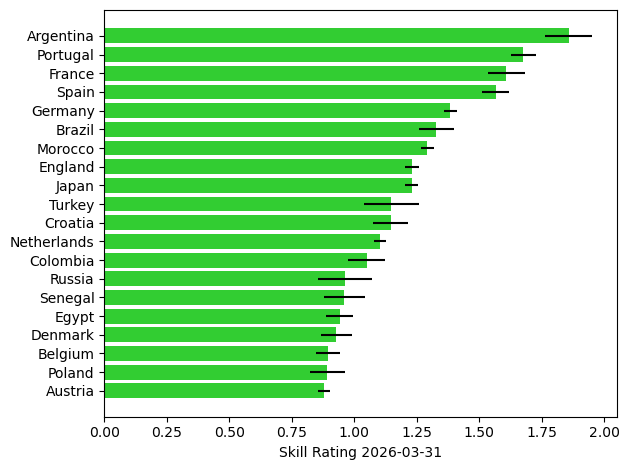

In [13]:
mean = filter_states.mean[-1]
top_team_inds = jnp.argsort(mean)[-20:]
top_team_names = [teams_id_to_name_dict[int(i)] for i in top_team_inds]
top_team_means = mean[top_team_inds]
cov = filter_states.chol_cov[-1] @ filter_states.chol_cov[-1].T
top_team_stds = jnp.sqrt(jnp.diag(cov) ** 2)[top_team_inds]

plt.figure()
plt.barh(top_team_names, top_team_means, xerr=top_team_stds, color="limegreen")
last_match_date = football_data["date"].max().strftime("%Y-%m-%d")
plt.xlabel(f"Skill Rating {last_match_date}")
plt.tight_layout()
plt.show()

#### Build and run the smoother
The filtering distribution gives us live estimates with uncertainty. However, for historical evaluation we want to use smoothing so that information is passed backwards too.

With `cuthbert` this is just as easy as filtering.

In [14]:
football_smoother = taylor.build_smoother(get_dynamics_log_density)
smoother_states = smoother(football_smoother, filter_states, match_data)

#### Ok so who are the best teams historically?

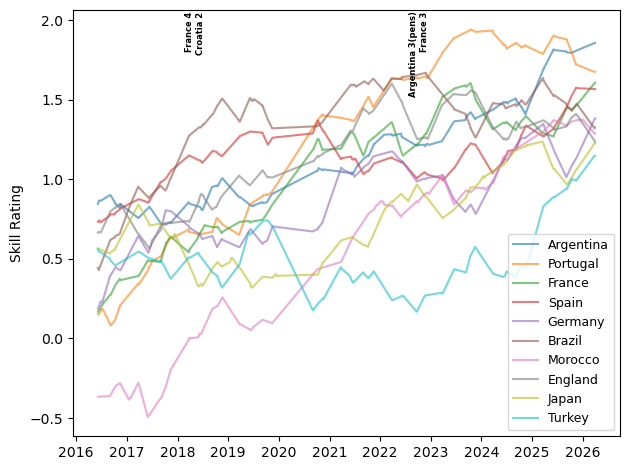

In [15]:
time_ind_start = -5000 #-10000
top_teams_over_time_inds = jnp.argsort(mean)[-10:][::-1]
top_team_names_over_time = [
    teams_id_to_name_dict[int(i)] for i in top_teams_over_time_inds
]
match_dates_over_time = football_data["date"][time_ind_start:]
top_team_means_over_time = smoother_states.mean[
    time_ind_start:, top_teams_over_time_inds
]
all_covs_diag = vmap(lambda x: jnp.diag(x @ x.T))(
    smoother_states.chol_cov[time_ind_start:]
)
top_team_stds_over_time = jnp.sqrt(all_covs_diag[:, top_teams_over_time_inds])

interesting_dates = {
    "France 4\nCroatia 2": "2018-07-15",
    "Argentina 3(pens)\nFrance 3": "2022-12-18",
}

plt.figure()
plt.plot(
    match_dates_over_time,
    top_team_means_over_time[:],
    label=top_team_names_over_time,
    alpha=0.6,
)

for name, date in interesting_dates.items():
    date = pd.to_datetime(date)
    # Add name as little annotation at the date, vertical orientation
    ylim_top = plt.ylim()[1]
    plt.annotate(
        name,
        (date, ylim_top - 0.01),  # type: ignore
        rotation=90,
        fontsize=6,
        fontweight="bold",
        va="top",
        ha="right",
    )

plt.legend(top_team_names_over_time, loc="lower right", fontsize=9)
plt.ylabel("Skill Rating")
plt.tight_layout()
plt.show()

#### Key Takeaways
- **Flexible model specification:** `cuthbert.gaussian.taylor` allows you to define state-space models using simple log-density functions, making it easy to work with complex, non-linear models like the Elo-style ranking model used here.
- **Filtering for online inference:** `cuthbert.filter` can be used to offline filtering on a full dataset, `filter_prepare` and `filter_combine` can be used to perform online filtering as new data arrives.
- **Smoothing for historical analysis:** While filtering provides online estimates, smoothing gives more accurate historical estimates by incorporating future information.

#### Working with chess data

The data is provided in the `lichess_tournament_fbjwIw0c_weekly-superblitz.pgn` file. Below we included some helper code that will load data in a Python list which you can process. Your goal is to adapt the football loader function `load_international_football_data`.

Please note that the data is probably too much for the Noteable server to work with: you'll need to use a suitable subset only. Use the football example as a guide.

Some suggestions:
- Inspect the elements of the `headers` list.
- We included some code to get a useful timestamp from the data.
- A possible mapping to football scores would be to declare (from the `'Result'` field):
    - a White win `'1-0'` to have a home score of 1 and away score 0
    - a Black win `'0-1'` to have a home score of 0 and away score 1
    - a Draw `'1/2-1/2'` to have a home score of 0 and away score 0
- You may extract rankings from the `ES98D/W5/lichess_tournament_fbjwIw0c_weekly-superblitz.csv` file.

In [16]:
import chess.pgn

In [17]:
headers = []
with open("lichess_tournament_fbjwIw0c_weekly-superblitz.pgn") as pgn:
    while True:
        h = chess.pgn.read_headers(pgn)
        if h is None:
            break
        headers.append(h)

Inspect the data structure of an element.

In [18]:
print(headers[0])

Headers(Event='Weekly SuperBlitz Arena', Site='https://lichess.org/14ueijo0', Date='2026.02.17', Round='-', White='raquaza', Black='gaikwaddinesh', Result='0-1', GameId='14ueijo0', UTCDate='2026.02.17', UTCTime='19:58:12', WhiteElo='2309', BlackElo='1923', WhiteRatingDiff='-11', BlackRatingDiff='+10', WhiteBerserk='true', BlackBerserk='true', Variant='Standard', TimeControl='180+0', ECO='A04', Termination='Normal')


### Chess Data

Now, we'll create a helper function to work with the chess dataset. We can map the Chess games similarly to the framework used for football analysis, where White plays as Home and Black plays as Away. We know that the Home side has an advantage in football, and White has been shown to have a positive advantage across game analysis. [[1]](https://doi.org/10.48550/arXiv.1212.2787) With this in mind, we can encode this directly into our observation model.

Games will be indexed by order sequence rather than using time stamps, as it is easier to identify skill fluctuation as discrete game phenomena than continuous time phenomena. The dynamics variance then scales as $\tau^2 \cdot \Delta k$ where $\Delta k$ is the number of games elapsed since a player last played, giving a sensible notion of drift per game.

We filter to players with at least 5 games to ensure posterior estimates are meaningfully informed by data rather than dominated by the prior.

In [19]:
def get_chess_data(headers, min_matches=35):
    records = []
    for h in headers:
        timestamp = pd.to_datetime(
            h["UTCDate"] + " " + h["UTCTime"], format="%Y.%m.%d %H:%M:%S"
        )
        records.append({
            "white": h["White"],
            "black": h["Black"],
            "result": h["Result"],
            "timestamp": timestamp,
        })

    df = pd.DataFrame(records).sort_values("timestamp").reset_index(drop=True)

    # count on full dataset, filter once — same approach as football example
    counts = pd.concat([df["white"], df["black"]]).value_counts()
    valid = set(counts[counts >= min_matches].index)
    df = df[df["white"].isin(valid) & df["black"].isin(valid)].reset_index(drop=True)

    df["game_index"] = df.index
    players = sorted(set(df["white"]) | set(df["black"]))
    player_to_id = {p: i for i, p in enumerate(players)}
    id_to_player = {i: p for i, p in enumerate(players)}

    result_map = {"1-0": 1, "0-1": 2, "1/2-1/2": 0}
    df["result_int"] = df["result"].map(result_map)
    df["white_id"] = df["white"].map(player_to_id)
    df["black_id"] = df["black"].map(player_to_id)

    return df, id_to_player, player_to_id

chess_data, id_to_player, player_to_id = get_chess_data(headers)
print("Number of players:", len(id_to_player))
print("Number of games:", len(chess_data))

Number of players: 37
Number of games: 131


We wrap the data into JAX arrays, same as the convention used in the `cuthbert`football example. We set a dummy observation, prepended at time zero so that the first real game constitutes the first update step.

In [20]:
num_players = len(id_to_player)

match_times = jnp.array(chess_data["game_index"], dtype=jnp.float32)
match_team_indices = jnp.array(chess_data[["white_id", "black_id"]], dtype=jnp.int32)
match_results = jnp.array(chess_data["result_int"])

match_times = jnp.concatenate([jnp.array([0.0]), match_times])
match_team_indices = jnp.concatenate([jnp.array([[-1, -1]]), match_team_indices])
match_results = jnp.concatenate([jnp.array([-1]), match_results])

match_times_prev = jnp.concatenate([jnp.array([-1.0]), match_times[:-1]])

match_data = MatchData(match_times, match_times_prev, match_team_indices, match_results)

Skills follow a Gaussian Random Walk (GRW) with variance $\tau^2 \Delta k$, initialised as $\mathcal{N}(0, 0.5)$. We reuse the helper functions in the football case. However, for the observation model, the probability of each outcome for skills $x^w$ (White) and $x^b$ (Black) is:

$$P(\text{White win}) = \sigma(x^w - x^b - \varepsilon),$$ 
$$P(\text{Black win}) = 1 - \sigma(x^w - x^b + \varepsilon),$$ 
$$P(\text{draw}) = 1 - P(W) - P(B)$$

The asymmetry introduced by $\varepsilon > 0$ encodes White's structural first-move advantage. This is in direct contrast to Elo, which treats both colours symmetrically by construction. We fix $\varepsilon = 0.3$ and $\tau = 0.05$ as in the football case.

In [21]:
init_sd = 0.5 ** 0.5
tau = 0.05
epsilon = 0.3

def get_init_log_density(model_inputs):
    def init_log_density(x):
        return norm.logpdf(x, 0, init_sd).sum()
    return init_log_density, jnp.zeros(num_players)

def get_dynamics_log_density(state, model_inputs):
    def dynamics_log_density(x_prev, x):
        return norm.logpdf(
            x,
            x_prev,
            jnp.sqrt((tau**2) * (model_inputs.time - model_inputs.time_prev)) + 1e-8,
        ).sum()
    return dynamics_log_density, jnp.zeros(num_players), jnp.zeros(num_players)

def get_chess_observation_func(state, model_inputs):
    def log_potential(x):
        x_white = x[model_inputs.team_indices[0]]
        x_black = x[model_inputs.team_indices[1]]

        prob_white_win = sigmoid(x_white - x_black - epsilon)
        prob_black_win = 1 - sigmoid(x_white - x_black + epsilon)
        prob_draw = 1 - prob_white_win - prob_black_win

        prob_array = jnp.array([prob_draw, prob_white_win, prob_black_win])
        return jnp.log(prob_array[model_inputs.result])

    return log_potential, state.mean

chess_filter = taylor.build_filter(
    get_init_log_density,
    get_dynamics_log_density,
    get_chess_observation_func,
    ignore_nan_dims=True,
)

At each step, the model propagates the skill prior forward by $\Delta k$ games, updating based on the observed result. The result is an estimate $p(x_k \mid y_{1:k})$, yielding best skill estimate given only past games.

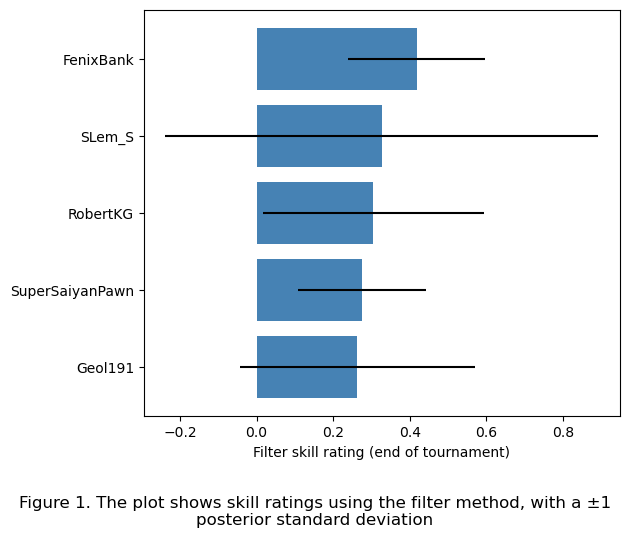

In [22]:
filter_states = filter(chess_filter, match_data)
mu = filter_states.mean[-1]
stds = jnp.sqrt(jnp.sum(filter_states.chol_cov[-1] ** 2, axis=1)) # use cholesky factor to avoid O(N^2) covar operation

rankings = pd.DataFrame({
    "player": [id_to_player[i] for i in range(mu.shape[0])],
    "skill": np.array(mu),
    "uncertainty": np.array(stds),
}).sort_values("skill", ascending=False).reset_index(drop=True)

top5 = rankings.head(5).iloc[::-1]

plt.figure()
plt.barh(top5["player"], top5["skill"], xerr=top5["uncertainty"], color="steelblue")
plt.xlabel("Filter skill rating (end of tournament)")

caption = "Figure 1. The plot shows skill ratings using the filter method, with a ±1 posterior standard deviation"
plt.figtext(0.5, -0.1, caption, wrap=True, horizontalalignment='center', fontsize=12)


plt.tight_layout()
plt.show()

We use a smoother to have a backward pass through the stored filter states, incorporating forecasted game results into past skill estimates. This yields $p(x_k \mid y_{1:K})$: whilst this requires all the data upfront, it offers a more accurate representation of skill. Visually, smoother trajectories are expected to be smoother (lower variance) and may revise early estimates substantially for players whose later results were informative.

We plot skill trajectories with $\pm 1$ standard deviation bands for the top 10 players by final smoothed skill, comparing filter and smoother estimates directly.

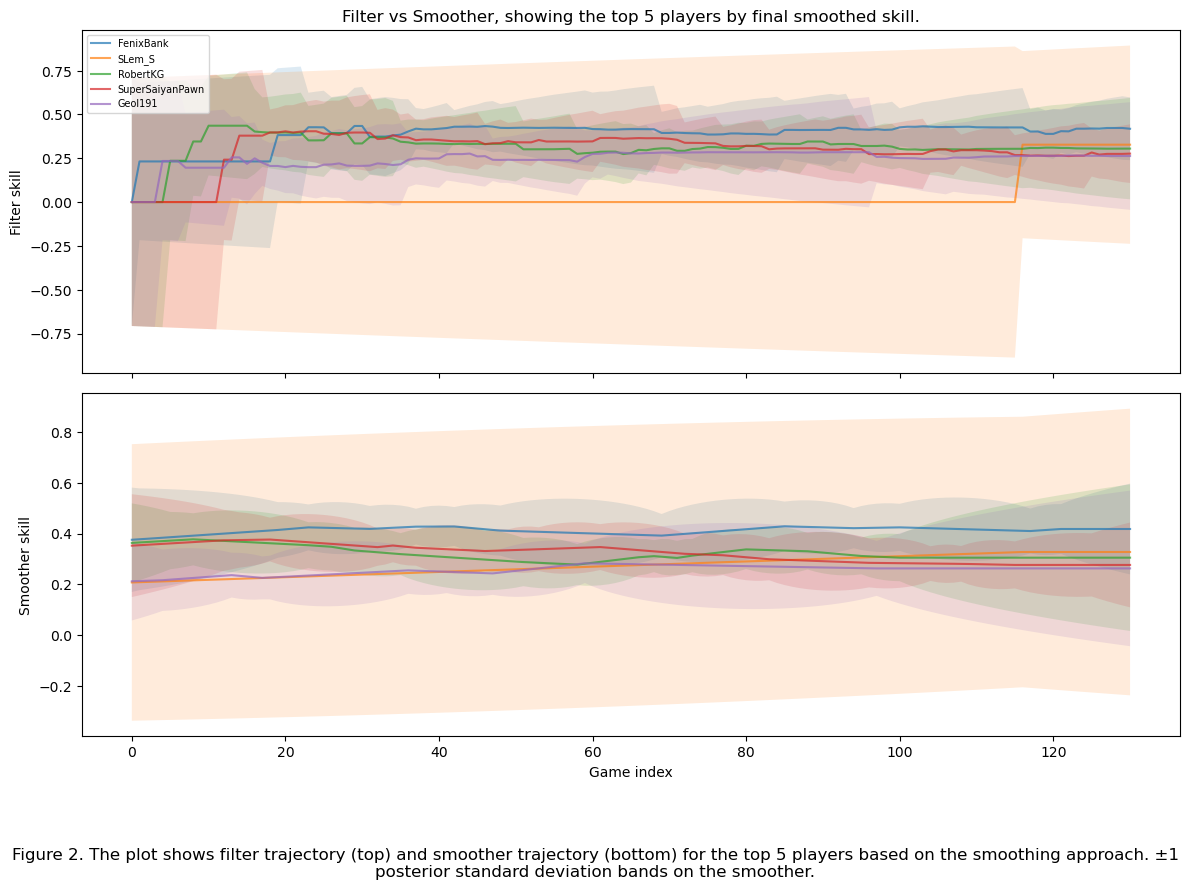

In [25]:
chess_smoother = taylor.build_smoother(get_dynamics_log_density)
smoother_states = smoother(chess_smoother, filter_states, match_data)

smooth_mean_final = smoother_states.mean[-1]
top_inds_smooth = jnp.argsort(smooth_mean_final)[-5:][::-1]
top_names_smooth = [id_to_player[int(i)] for i in top_inds_smooth]

game_indices = chess_data["game_index"].values

all_filter_means = filter_states.mean[1:, top_inds_smooth]
all_smoother_means = smoother_states.mean[1:, top_inds_smooth]

all_filter_covs = vmap(lambda c: jnp.diag(c @ c.T))(filter_states.chol_cov[1:])
all_smoother_covs = vmap(lambda c: jnp.diag(c @ c.T))(smoother_states.chol_cov[1:])

all_filter_stds = jnp.sqrt(all_filter_covs[:, top_inds_smooth])
all_smoother_stds = jnp.sqrt(all_smoother_covs[:, top_inds_smooth])

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

for i, name in enumerate(top_names_smooth):
    axes[0].plot(game_indices, all_filter_means[:, i], label=name, alpha=0.7)
    axes[0].fill_between(
        game_indices,
        all_filter_means[:, i] - all_filter_stds[:, i],
        all_filter_means[:, i] + all_filter_stds[:, i],
        alpha=0.15,
    )

for i, name in enumerate(top_names_smooth):
    axes[1].plot(game_indices, all_smoother_means[:, i], label=name, alpha=0.7)
    axes[1].fill_between(
        game_indices,
        all_smoother_means[:, i] - all_smoother_stds[:, i],
        all_smoother_means[:, i] + all_smoother_stds[:, i],
        alpha=0.15,
    )

axes[0].set_ylabel("Filter skill")
axes[1].set_ylabel("Smoother skill")
axes[1].set_xlabel("Game index")
axes[0].legend(fontsize=7, loc="upper left")
axes[0].set_title("Filter vs Smoother, showing the top 5 players by final smoothed skill.")

caption = "Figure 2. The plot shows filter trajectory (top) and smoother trajectory (bottom) for the top 5 players based on the smoothing approach. ±1 posterior standard deviation bands on the smoother."
plt.figtext(0.5, -0.1, caption, wrap=True, horizontalalignment='center', fontsize=12)

plt.tight_layout()
plt.show()

We compare the smoother results with the tournament data in the provided CSV file to compare model performance with the reality.

In [24]:
tournament_data = pd.read_csv("lichess_tournament_fbjwIw0c_weekly-superblitz.csv")

final_smooth_mean = smoother_states.mean[-1]
final_smooth_cov = smoother_states.chol_cov[-1] @ smoother_states.chol_cov[-1].T
final_smooth_std = jnp.sqrt(jnp.diag(final_smooth_cov))

rankings_df = pd.DataFrame({
    "player": [id_to_player[i] for i in range(num_players)],
    "skill": final_smooth_mean,
    "uncertainty": final_smooth_std,
}).sort_values("skill", ascending=False).reset_index(drop=True)

rankings_df["model_rank"] = rankings_df.index + 1

rankings_df = rankings_df.merge(
    tournament_data[["Username", "Rank"]].rename(columns={"Username": "player", "Rank": "official_rank"}),
    on="player",
    how="left",
)

print(rankings_df.head(5).to_string(index=False))

         player    skill  uncertainty  model_rank  official_rank
      FenixBank 0.418169     0.179213           1              2
         SLem_S 0.327366     0.565635           2            330
       RobertKG 0.304972     0.289197           3              9
SuperSaiyanPawn 0.276313     0.167388           4              6
        Geol191 0.262663     0.306978           5             59


Most of the analysis conducted is mentioned in the report.